# Dysbiosis Calls and Defense Score (Recalled Species)

Species-level version of `Recall_genera_update_paper_results/dysbiosis_calls_and_defense_score_recalled_genera.ipynb`.

Species come from `Oct_2026_recalled_species/lic16s_species_relabund.csv`. Taxa that couldn't be resolved to species keep a higher-rank label in the `Species` column (e.g. `g__Janthinobacterium_571130 Genus`, `f__SbA1 Family`) and are treated as one species each, as unresolved genera were in the genus table. Species under 0.05% of a sample (`AbundR == 0`) are dropped, which matches the cleaning of the recalled-genera table.

**Dysbiosis definition (recalled species):**
- **Rare species:** present in < 10% of seasonal plant samples, as in `core_and_rare_species_definitions_and_temporal_patterns.ipynb`. Species seen only in circadian samples (0% seasonal prevalence) also count as rare.
- **Core species:** present in > 80% of seasonal plant samples.
- **Dysbiotic:** a sample whose rare species make up more than `rare_species_abundance_threshold` percent of its reads.

The threshold is set to 3% for now, which calls about as many samples as the old species-level rule (9.5%) and the recalled-genera calls. It is still to be revisited: see the threshold plot below and `to_revisit.txt`.

This notebook saves the calls to `Generated_data/dysbiosis_calls_recalled_species.csv`. The PCA and differential-expression notebooks in this folder read that file, so **change the threshold here and re-run them in order**.

The recalled-genera calls (`dysbiosis_calls_recalled_genera.csv`) are only used for comparison.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from skbio.diversity.alpha import shannon
from scipy.stats import zscore
from scipy.stats import ttest_ind

In [2]:
###Define Thresholds
rare_species_definition_threshold = 0.1  # prevalence in seasonal plant samples
core_species_definition_threshold = 0.8
rare_species_abundance_threshold = 3.0  # % of the sample's reads in rare species

In [3]:
transcriptome = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/plate1_5_tpm_normalized.csv",
    index_col=0,
)
rows_to_drop_expression_data = [
    "A2450525897_n01_undetermined",
    "A2449446903_n01_undetermined",
    "B250508004_n01_undetermined",
    "B2449500127_n01_undetermined",
]
transcriptome = transcriptome.drop(index=rows_to_drop_expression_data)
transcriptome = transcriptome.sort_index()
metadata = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/Plates_1_to_5_metadata_merged_luke.csv",
    index_col=0,
)
metadata = metadata.drop(
    columns=[
        "arb.sort",
        "sample-id",
        "Ambiguous Unstranded",
        "Ambiguous Forward",
        "Multimapping",
        "Unmapped Over Mapped",
    ]
)
metadata["Date and Time"] = metadata["date"] + " " + metadata["time"]
luke_time_data_format = "%-m/%-d/%y %-H:%-M"
metadata["Date and Time"] = pd.to_datetime(
    metadata["Date and Time"], format=luke_time_data_format
)

## Get plate 5 samples and remove what they replaced from the metadata to avoid duplicates
plate_5_replacements = metadata.loc[metadata["rnaprepplate"] == "LICRNA_05"]
non_plate_5_samples = metadata.loc[metadata["rnaprepplate"] != "LICRNA_05"]
replaced_samples = non_plate_5_samples.loc[
    non_plate_5_samples["sampID"].isin(plate_5_replacements["sampID"])
]
trimmed_metadata = metadata.drop(index=replaced_samples.index)
### For remaining duplicated sampIDs, drop the transcriptome with fewer total reads
double_duplicates = (
    trimmed_metadata.loc[trimmed_metadata.duplicated(subset="sampID", keep=False)]
    .sort_values(by="Total Reads")
    .drop_duplicates(subset="sampID", keep="first")
)
trimmed_metadata = trimmed_metadata.drop(index=double_duplicates.index)
### Drop failed libraries with too few reads (e.g. LIC162 has 66 total reads)
min_total_reads = 250_000
low_read_samples = trimmed_metadata.index[trimmed_metadata["Total Reads"] < min_total_reads]
trimmed_metadata = trimmed_metadata.drop(index=low_read_samples)
print(f"Dropped {len(low_read_samples)} transcriptomes with < {min_total_reads:,} total reads")
trimmed_transcriptome = transcriptome.loc[trimmed_metadata.index]
print("Transcriptomes after removing replicates:", len(trimmed_metadata))
defense_gene_list = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/Generated_data/load_correlated_genes_union_GO_and_FLG_plates_1_to_5.csv"
)

Dropped 6 transcriptomes with < 250,000 total reads
Transcriptomes after removing replicates: 426


## Rare and core species

In [4]:
### Recalled species table. Species under 0.05% of a sample (AbundR == 0, which
### includes the zero rows) are dropped, as in the recalled-genera table
min_abundR = 1
### Plant samples missing from the recalled-genera table (LIC148, LIC162, LIC584 have
### < 1,600 16S reads; LIC577 unknown). Kept for now: see to_revisit.txt
samples_to_drop = []  # ["LIC148", "LIC162", "LIC577", "LIC584"]
microbiome_abundance = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/Oct_2026_recalled_species/lic16s_species_relabund.csv"
)
microbiome_abundance = microbiome_abundance.loc[
    (microbiome_abundance["AbundR"] >= min_abundR)
    & ~microbiome_abundance["Sample"].isin(samples_to_drop)
].copy()
# No seascirc column in the species table: circadian timepoints start with "c"
microbiome_abundance["seascirc"] = np.where(
    microbiome_abundance["timepoint"].str.startswith("c"), "circadian", "seasonal"
)
plant_microbiome = microbiome_abundance.loc[microbiome_abundance["sample.type"] == "plant"]

# Sample x species abundance as % of each sample's reads (absent species = 0)
species_abundance_matrix = pd.pivot_table(
    plant_microbiome,
    values="Abundance",
    index="Sample",
    columns="Species",
    aggfunc="sum",
    fill_value=0,
)
species_abundance_matrix = (
    species_abundance_matrix.div(species_abundance_matrix.sum(axis=1), axis=0) * 100
)

seasonal_samples = plant_microbiome.loc[
    plant_microbiome["seascirc"] == "seasonal", "Sample"
].unique()
seasonal_prevalence = (species_abundance_matrix.loc[seasonal_samples] > 0).mean()

rare_species = seasonal_prevalence.index[
    seasonal_prevalence < rare_species_definition_threshold
].tolist()
core_species = seasonal_prevalence.index[
    seasonal_prevalence > core_species_definition_threshold
].tolist()

print("Plant microbiome samples:", species_abundance_matrix.shape[0])
print("Seasonal samples (prevalence denominator):", len(seasonal_samples))
print(f"Rare species: {len(rare_species)} ({(seasonal_prevalence[rare_species] == 0).sum()} only seen in circadian samples)")
print(f"Core species: {len(core_species)}")

Plant microbiome samples: 432
Seasonal samples (prevalence denominator): 224
Rare species: 434 (46 only seen in circadian samples)
Core species: 40


In [5]:
present = species_abundance_matrix > 0
sample_summary = pd.DataFrame(
    {
        "shannon_diversity": species_abundance_matrix.apply(
            lambda row: shannon(row.to_numpy()), axis=1
        ),
        "total_species_present": present.sum(axis=1),
        "n_core_species_present": present[core_species].sum(axis=1),
        "has_rare_species": present[rare_species].any(axis=1),
        "lacking_core_species": ~present[core_species].all(axis=1),
        "rare_species_total_abund": species_abundance_matrix[rare_species].sum(axis=1),
    }
)

# Add columns to metadata using the sampID column (not the index). Transcriptomes
# without a microbiome profile get 0 rare abundance, as in the original.
for column in sample_summary.columns:
    trimmed_metadata[column] = trimmed_metadata["sampID"].map(sample_summary[column])
print(
    "Transcriptomes without a microbiome profile:",
    trimmed_metadata["rare_species_total_abund"].isna().sum(),
)
trimmed_metadata["rare_species_total_abund"] = trimmed_metadata[
    "rare_species_total_abund"
].fillna(0.0)

trimmed_metadata[["sampID", "timepoint"] + sample_summary.columns.tolist()]

Transcriptomes without a microbiome profile: 0


,sampID,timepoint,shannon_diversity,total_species_present,n_core_species_present,has_rare_species,lacking_core_species,rare_species_total_abund
filename,,,,,,,,
A2450525897_n01_LICRNA01_A01,LIC001,t01,4.124876,149,40,True,False,3.115181
A2450525897_n01_LICRNA01_B01,LIC002,t01,3.909103,127,34,True,True,9.019024
A2450525897_n01_LICRNA01_C01,LIC003,t01,4.218445,140,38,True,True,5.245414
A2450525897_n01_LICRNA01_E01,LIC005,t01,3.086702,112,39,True,True,2.218603
A2450525897_n01_LICRNA01_F01,LIC006,t01,3.046134,99,36,True,True,0.561949
...,...,...,...,...,...,...,...,...
A2534491401_n01_LICRNA05_D12,LIC542,c1_t13,3.751845,100,36,True,True,1.424918
A2534491401_n01_LICRNA05_E12,LIC495,c1_t09,3.191887,91,34,True,True,0.609979
A2534491401_n01_LICRNA05_F12,LIC421,c1_t04,3.037315,74,34,True,True,0.477208


## Picking the rare-species abundance threshold

Number of transcriptome samples called dysbiotic at each rare-species abundance cutoff. The dashed horizontal line is the number of samples called dysbiotic by the old species-level rule (rare species = present in ≤ 37 of 372 samples, dysbiotic = > 9.5% abundance in rare species), rebuilt here on the same transcriptome samples. The orange line shows how many of the new calls were also dysbiotic under the old rule.

In [6]:
# Old species-level calls, rebuilt as in the original notebook
old_microbiome = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/Microbiome/lic2024_16S_rab.csv"
)
old_species_table = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/Generated_data/species_core_results.csv"
)
old_rare_species = set(
    old_species_table.loc[old_species_table["n_samples_present"] <= 37, "Species"]
)
old_rare_abund = (
    old_microbiome.loc[old_microbiome["Species"].isin(old_rare_species)]
    .groupby("plantID")["AbundR100"]
    .sum()
)
trimmed_metadata["old_rare_species_total_abundR100"] = (
    trimmed_metadata["sampID"].map(old_rare_abund).fillna(0.0)
)
old_dysbiotic = trimmed_metadata["old_rare_species_total_abundR100"] > 9.5
print(f"Old species-level dysbiotic samples: {old_dysbiotic.sum()} / {len(trimmed_metadata)}")

Old species-level dysbiotic samples: 50 / 426


,threshold,n_dysbiotic,n_also_old_dysbiotic
10,1.0,177,46
20,2.0,85,41
30,3.0,52,34
50,5.0,24,20
75,7.5,6,5
95,9.5,5,4
100,10.0,3,2
150,15.0,1,1


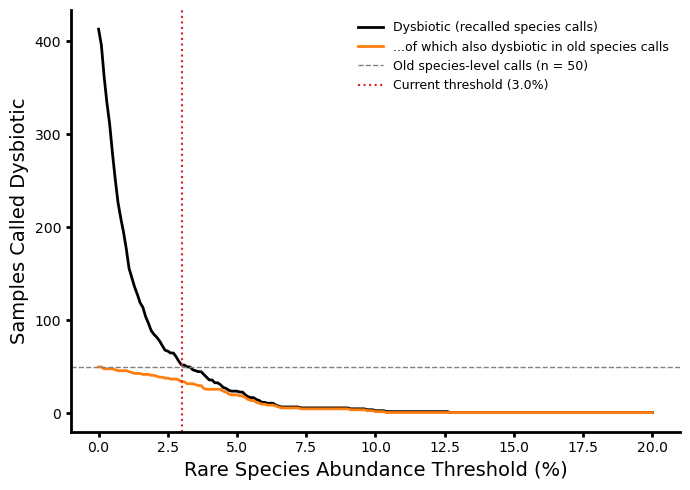

In [7]:
thresholds = np.round(np.arange(0, 20.01, 0.1), 2)
threshold_curve = pd.DataFrame(
    {
        "threshold": thresholds,
        "n_dysbiotic": [
            int((trimmed_metadata["rare_species_total_abund"] > t).sum())
            for t in thresholds
        ],
        "n_also_old_dysbiotic": [
            int(((trimmed_metadata["rare_species_total_abund"] > t) & old_dysbiotic).sum())
            for t in thresholds
        ],
    }
)
old_dysbiotic_count = int(old_dysbiotic.sum())

fig, ax = plt.subplots(figsize=(7, 5))
fig.patch.set_facecolor("white")
ax.plot(
    threshold_curve["threshold"],
    threshold_curve["n_dysbiotic"],
    color="black",
    linewidth=2,
    label="Dysbiotic (recalled species calls)",
)
ax.plot(
    threshold_curve["threshold"],
    threshold_curve["n_also_old_dysbiotic"],
    color="tab:orange",
    linewidth=2,
    label="...of which also dysbiotic in old species calls",
)
ax.axhline(
    old_dysbiotic_count,
    color="gray",
    linestyle="dashed",
    linewidth=1,
    label=f"Old species-level calls (n = {old_dysbiotic_count})",
)
ax.axvline(
    rare_species_abundance_threshold,
    color="tab:red",
    linestyle="dotted",
    linewidth=1.5,
    label=f"Current threshold ({rare_species_abundance_threshold}%)",
)
plt.xlabel("Rare Species Abundance Threshold (%)", fontsize=14)
plt.ylabel("Samples Called Dysbiotic", fontsize=14)
sns.despine()
ax.spines["bottom"].set_color("black")
ax.spines["bottom"].set_linewidth(2)
ax.spines["left"].set_color("black")
ax.spines["left"].set_linewidth(2)
ax.tick_params(axis="both", width=2)
ax.legend(frameon=False, fontsize=9)
plt.tight_layout()

threshold_curve.loc[threshold_curve["threshold"].isin([1.0, 2.0, 3.0, 5.0, 7.5, 9.5, 10.0, 15.0])]

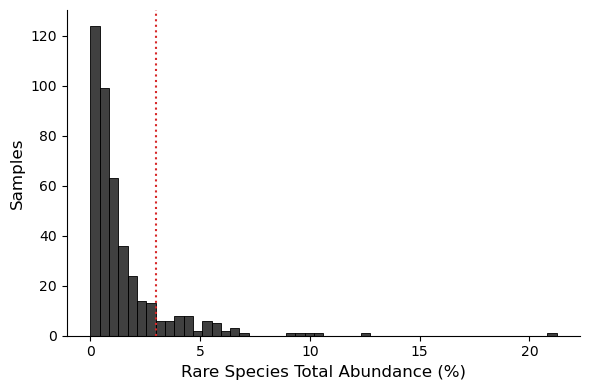

In [8]:
fig, ax = plt.subplots(figsize=(6, 4))
fig.patch.set_facecolor("white")
sns.histplot(trimmed_metadata["rare_species_total_abund"], bins=50, color="black", ax=ax)
ax.axvline(rare_species_abundance_threshold, color="tab:red", linestyle="dotted")
plt.xlabel("Rare Species Total Abundance (%)", fontsize=12)
plt.ylabel("Samples", fontsize=12)
sns.despine()
plt.tight_layout()

## Dysbiosis calls

In [9]:
trimmed_metadata["Dysbiosis Status"] = "Not Dysbiotic"
trimmed_metadata.loc[
    trimmed_metadata["rare_species_total_abund"] > rare_species_abundance_threshold,
    "Dysbiosis Status",
] = "Dysbiotic"
print(trimmed_metadata["Dysbiosis Status"].value_counts().to_string())

# Save one row per microbiome sample for the PCA / DE notebooks
dysbiosis_calls = sample_summary.assign(
    rare_species_abundance_threshold=rare_species_abundance_threshold,
    **{
        "Dysbiosis Status": np.where(
            sample_summary["rare_species_total_abund"] > rare_species_abundance_threshold,
            "Dysbiotic",
            "Not Dysbiotic",
        )
    },
)
dysbiosis_calls.index.name = "sampID"
dysbiosis_calls.to_csv(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/Generated_data/dysbiosis_calls_recalled_species.csv"
)

Dysbiosis Status
Not Dysbiotic    374
Dysbiotic         52


### Comparison with old species-level calls and recalled-genera calls

The recalled-genera calls are read from `dysbiosis_calls_recalled_genera.csv` (rare genera < 10% prevalence, > 1% of reads).

In [10]:
genus_calls = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/Generated_data/dysbiosis_calls_recalled_genera.csv",
    index_col="sampID",
)["Dysbiosis Status"]
trimmed_metadata["Genus Dysbiosis Status"] = trimmed_metadata["sampID"].map(genus_calls)
trimmed_metadata["Old Species Dysbiosis Status"] = np.where(
    old_dysbiotic, "Dysbiotic", "Not Dysbiotic"
)

print("Recalled species calls vs old species-level calls:")
display(pd.crosstab(trimmed_metadata["Dysbiosis Status"], trimmed_metadata["Old Species Dysbiosis Status"], margins=True))
print("Recalled species calls vs recalled genus calls:")
display(pd.crosstab(trimmed_metadata["Dysbiosis Status"], trimmed_metadata["Genus Dysbiosis Status"], margins=True))

Recalled species calls vs old species-level calls:


Old Species Dysbiosis Status,Dysbiotic,Not Dysbiotic,All
Dysbiosis Status,,,
Dysbiotic,34,18,52
Not Dysbiotic,16,358,374
All,50,376,426


Recalled species calls vs recalled genus calls:


Genus Dysbiosis Status,Dysbiotic,Not Dysbiotic,All
Dysbiosis Status,,,
Dysbiotic,30,21,51
Not Dysbiotic,26,347,373
All,56,368,424


## Defense score vs dysbiosis

In [11]:
transcriptome_in_defense_gene_list = trimmed_transcriptome.loc[
    :, trimmed_transcriptome.columns.isin(defense_gene_list["gene"].tolist())
]
summed_zscored_transcriptome = transcriptome_in_defense_gene_list.apply(zscore).sum(
    axis=1
) / len(defense_gene_list)
circadian_metadata_w_load_info = trimmed_metadata.merge(
    summed_zscored_transcriptome.rename("Summed Defense Z Score"),
    left_index=True,
    right_index=True,
)
circadian_metadata_w_load_info.groupby("Dysbiosis Status")["Summed Defense Z Score"].agg(
    ["mean", "median", "count"]
)

,mean,median,count
Dysbiosis Status,,,
Dysbiotic,0.321547,0.122964,52
Not Dysbiotic,-0.044707,-0.170610,374


In [12]:
dysbiotic_scores = circadian_metadata_w_load_info.loc[
    circadian_metadata_w_load_info["Dysbiosis Status"] == "Dysbiotic",
    "Summed Defense Z Score",
]
nondysbiotic_scores = circadian_metadata_w_load_info.loc[
    circadian_metadata_w_load_info["Dysbiosis Status"] == "Not Dysbiotic",
    "Summed Defense Z Score",
]
t_stat, p_value = ttest_ind(dysbiotic_scores, nondysbiotic_scores)
print(f"t = {t_stat:.3f}, P-value: {p_value}")

t = 4.169, P-value: 3.712961530024628e-05


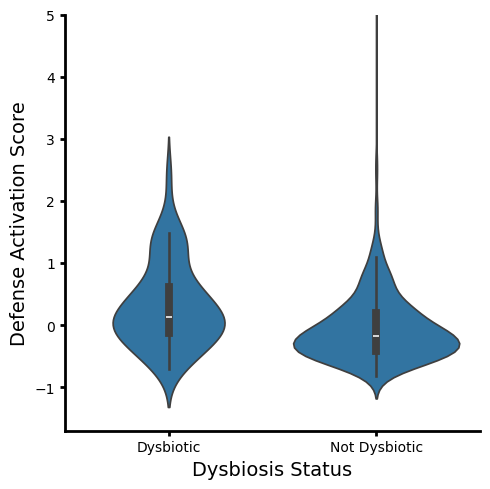

In [13]:
fig, ax = plt.subplots(figsize=(5, 5))
fig.patch.set_facecolor("white")
ax = sns.violinplot(
    data=circadian_metadata_w_load_info,
    x="Dysbiosis Status",
    y="Summed Defense Z Score",
    order=["Dysbiotic", "Not Dysbiotic"],
    inner="box",
    common_norm=True,
)
plt.xlabel("Dysbiosis Status", fontsize=14)
plt.ylabel("Defense Activation Score", fontsize=14)
sns.despine()
ax.spines["bottom"].set_color("black")
ax.spines["bottom"].set_linewidth(2)
ax.spines["left"].set_color("black")
ax.spines["left"].set_linewidth(2)
ax.tick_params(axis="both", width=2)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
plt.ylim(-1.7, 5)
plt.tight_layout()

In [14]:
# circadian_metadata_w_load_info.to_csv(
#     "/Users/michael/Library/CloudStorage/GoogleDrive-mikepassalacqua@gmail.com/My Drive/Bergleson Lab Documents/Luke Terrace/All_used_and_generated_terrace_data/Stats_7_28_Files/dysbiosis_status_and_defense_score_recalled_species.csv",
#     index=True,
# )

Dysbiosis Status
Dysbiotic          8
Not Dysbiotic    111


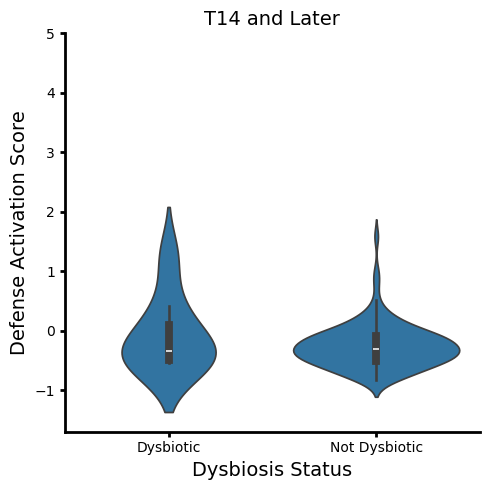

In [15]:
t14_and_later = circadian_metadata_w_load_info.loc[
    pd.to_numeric(
        circadian_metadata_w_load_info["timepoint"]
        .astype(str)
        .str.extract(r"(\d+)", expand=False),
        errors="coerce",
    )
    >= 14
]
print(t14_and_later.groupby("Dysbiosis Status")["Summed Defense Z Score"].count().to_string())

fig, ax = plt.subplots(figsize=(5, 5))
fig.patch.set_facecolor("white")
ax = sns.violinplot(
    data=t14_and_later,
    x="Dysbiosis Status",
    y="Summed Defense Z Score",
    order=["Dysbiotic", "Not Dysbiotic"],
    inner="box",
    common_norm=True,
)
plt.xlabel("Dysbiosis Status", fontsize=14)
plt.ylabel("Defense Activation Score", fontsize=14)
plt.title("T14 and Later", fontsize=14)
sns.despine()
ax.spines["bottom"].set_color("black")
ax.spines["bottom"].set_linewidth(2)
ax.spines["left"].set_color("black")
ax.spines["left"].set_linewidth(2)
ax.tick_params(axis="both", width=2)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
plt.ylim(-1.7, 5)
plt.tight_layout()

Experiment Type         Dysbiosis Status
Circadian Experiment 1  Dysbiotic             4
                        Not Dysbiotic       100
Circadian Experiment 2  Dysbiotic             8
                        Not Dysbiotic        91


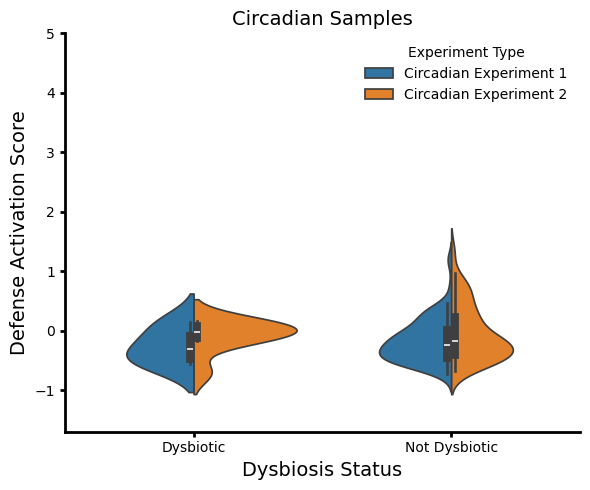

In [16]:
circadian_only = circadian_metadata_w_load_info.loc[
    circadian_metadata_w_load_info["Experiment Type"].isin(
        ["Circadian Experiment 1", "Circadian Experiment 2"]
    )
]
print(circadian_only.groupby(["Experiment Type", "Dysbiosis Status"]).size().to_string())

fig, ax = plt.subplots(figsize=(6, 5))
fig.patch.set_facecolor("white")
ax = sns.violinplot(
    data=circadian_only,
    x="Dysbiosis Status",
    y="Summed Defense Z Score",
    hue="Experiment Type",
    order=["Dysbiotic", "Not Dysbiotic"],
    inner="box",
    common_norm=True,
    split=True,
)
plt.xlabel("Dysbiosis Status", fontsize=14)
plt.ylabel("Defense Activation Score", fontsize=14)
plt.title("Circadian Samples", fontsize=14)
sns.despine()
ax.spines["bottom"].set_color("black")
ax.spines["bottom"].set_linewidth(2)
ax.spines["left"].set_color("black")
ax.spines["left"].set_linewidth(2)
ax.tick_params(axis="both", width=2)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
plt.ylim(-1.7, 5)
plt.legend(title="Experiment Type", frameon=False)
plt.tight_layout()

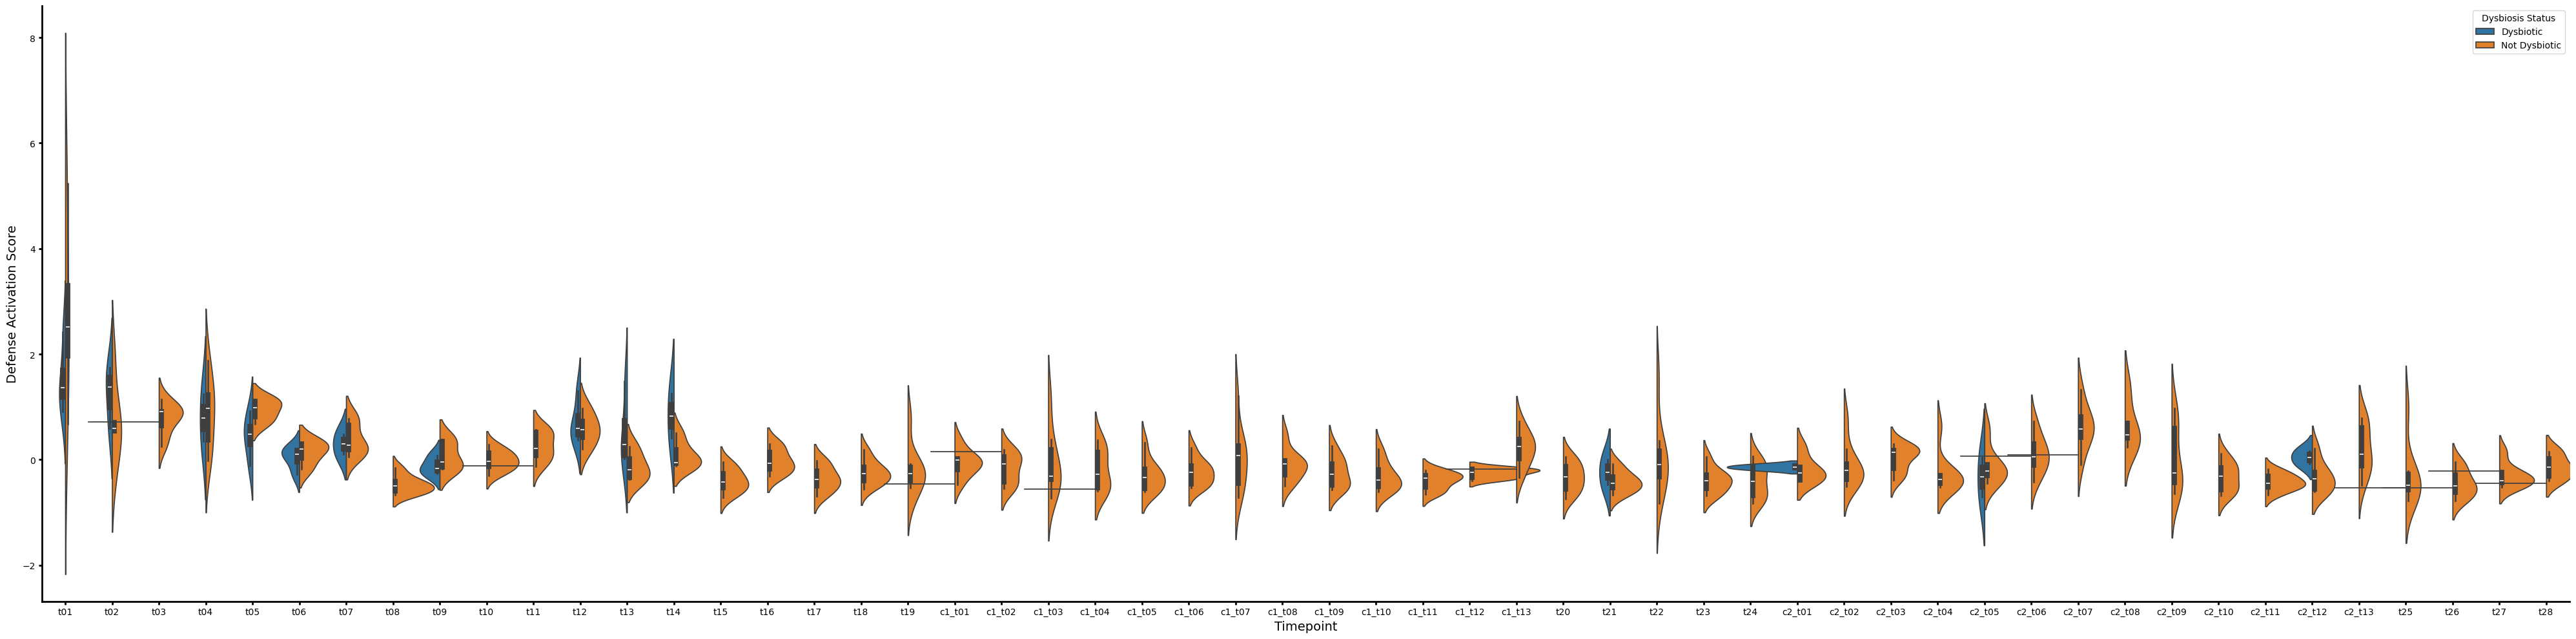

In [17]:
fig, ax = plt.subplots(figsize=(40, 10))
fig.patch.set_facecolor("white")
ax = sns.violinplot(
    data=circadian_metadata_w_load_info.sort_values("Date and Time"),
    x="timepoint",
    y="Summed Defense Z Score",
    hue="Dysbiosis Status",
    hue_order=["Dysbiotic", "Not Dysbiotic"],
    width=3,
    split=True,
    inner="box",
)
plt.xlabel("Timepoint", fontsize=14)
plt.ylabel("Defense Activation Score", fontsize=14)
sns.despine()
ax.spines["bottom"].set_color("black")
ax.spines["bottom"].set_linewidth(2)
ax.spines["left"].set_color("black")
ax.spines["left"].set_linewidth(2)
ax.tick_params(axis="both", width=2)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
plt.tight_layout()